In [3]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [4]:
df=pd.read_csv('ai4i2020.csv')

In [5]:
df.shape

(10000, 14)

In [6]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [8]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [9]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [12]:
df['Product ID'].unique()

<ArrowStringArray>
['M14860', 'L47181', 'L47182', 'L47183', 'L47184', 'M14865', 'L47186',
 'L47187', 'M14868', 'M14869',
 ...
 'L57170', 'M24851', 'L57172', 'L57173', 'L57174', 'M24855', 'H39410',
 'M24857', 'H39412', 'M24859']
Length: 10000, dtype: str

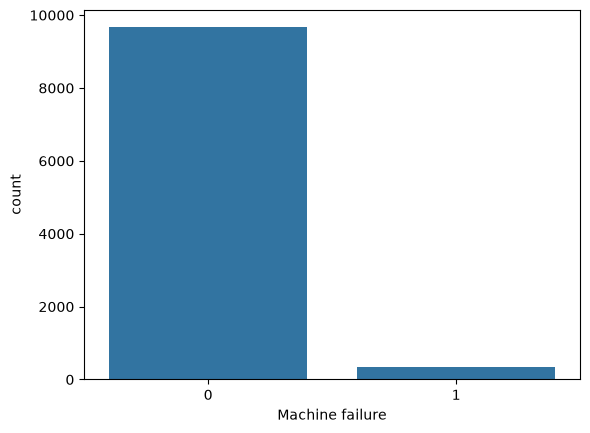

In [13]:
sns.countplot(data=df, x='Machine failure')
plt.show()

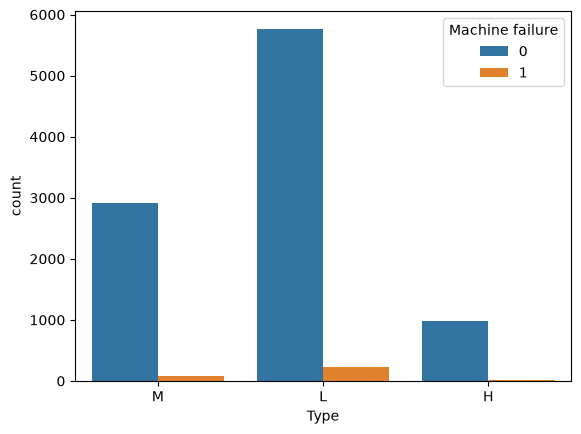

In [14]:
sns.countplot(data=df, x='Type', hue='Machine failure')
plt.show()

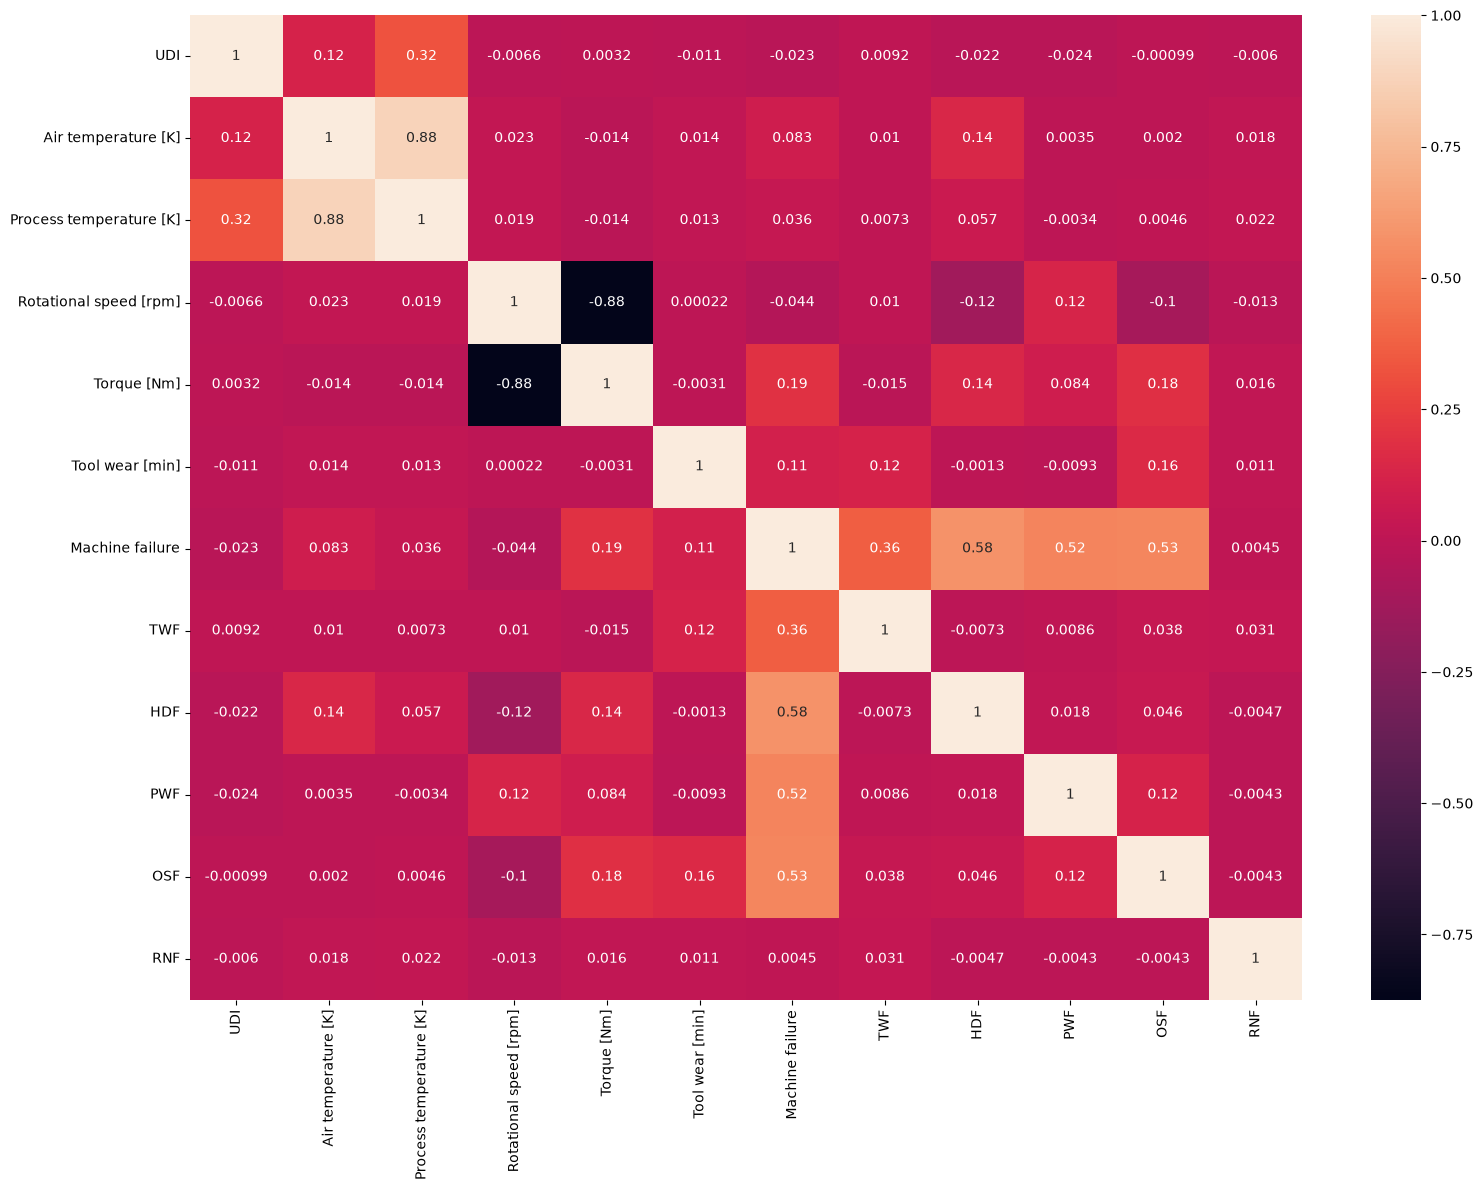

In [15]:
plt.figure(figsize=(16, 12))
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.tight_layout()

In [16]:
df['temp_diff']= df['Process temperature [K]']-df['Air temperature [K]']
df['power']= df['Torque [Nm]']* df['Rotational speed [rpm]']*2*np.pi / 60
df['wear_torque']= df['Tool wear [min]'] * df['Torque [Nm]']

In [17]:
num_features = df.select_dtypes(include='number') 
Q1=num_features.quantile(.25)
Q3=num_features.quantile(.75)
IQR=Q3-Q1
lower_bound=Q1-IQR*1.5
upper_bound=Q3+IQR*1.5

outliers = (num_features < lower_bound) | (num_features > upper_bound) 
print(outliers.sum())

UDI                          0
Air temperature [K]          0
Process temperature [K]      0
Rotational speed [rpm]     418
Torque [Nm]                 69
Tool wear [min]              0
Machine failure            339
TWF                         46
HDF                        115
PWF                         95
OSF                         98
RNF                         19
temp_diff                    0
power                       60
wear_torque                 20
dtype: int64


<Axes: xlabel='Rotational speed [rpm]', ylabel='Count'>

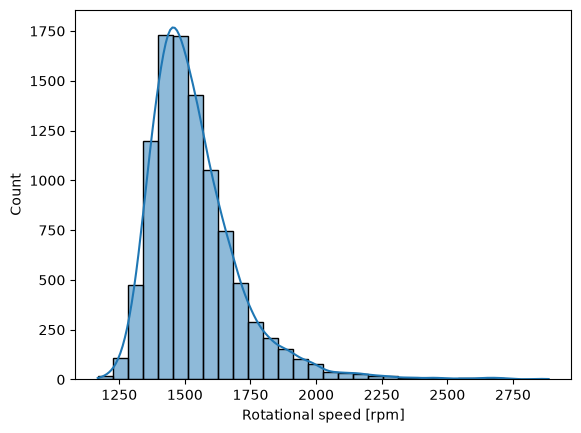

In [18]:
sns.histplot(data=df,x='Rotational speed [rpm]',bins=30,kde=True)

In [19]:
num_features.skew()

UDI                         0.000000
Air temperature [K]         0.114274
Process temperature [K]     0.015027
Rotational speed [rpm]      1.993171
Torque [Nm]                -0.009517
Tool wear [min]             0.027292
Machine failure             5.151852
TWF                        14.644462
HDF                         9.164789
PWF                        10.114516
OSF                         9.953916
RNF                        22.879570
temp_diff                  -0.072484
power                       0.008257
wear_torque                 0.469547
dtype: float64

Rotational speed [rpm]   use FT

In [20]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,temp_diff,power,wear_torque
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,10.5,6951.590560,0.0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,10.5,6826.722724,138.9
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,10.4,7749.387543,247.0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,10.4,5927.504659,276.5
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,10.5,5897.816608,360.0


In [21]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF',
       'temp_diff', 'power', 'wear_torque'],
      dtype='str')

In [22]:
df['RNF'].unique()

array([0, 1])

In [23]:
from sklearn.model_selection import train_test_split

skewed_col=['Rotational speed [rpm]','temp_diff','wear_torque']
other_numeric_col=['Air temperature [K]',
       'Process temperature [K]','Torque [Nm]',
       'Tool wear [min]','power']
catagorical_col =['Type']
# binary_col=['TWF', 'HDF', 'PWF', 'OSF',
#       'RNF']
feature_col=skewed_col+other_numeric_col+catagorical_col    #+binary_col
x = df[feature_col] 
y = df['Machine failure']

X_train, X_test, y_train, y_test = train_test_split(x, y,test_size=0.2,random_state=42,stratify=y)

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer,StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer

skew_pipeline=Pipeline(steps=[
    ('power_transform', PowerTransformer(method='yeo-johnson')),
    ('scale',StandardScaler())
])

numeric_pipeline=Pipeline(steps=[
    ('scale',StandardScaler())
])

catagorical_pipeline = Pipeline(steps=[
     ('encode', OneHotEncoder(handle_unknown='ignore'))
])

# binary_pipeline = 'passthrough'

In [25]:
preprocesser=ColumnTransformer(transformers=[
    ('skew_pipeline',skew_pipeline,skewed_col),
    ('numeric_pipeline',numeric_pipeline,other_numeric_col),
    ('catagorical_pipeline',catagorical_pipeline,catagorical_col),
    # ('binary_pipeline','passthrough',binary_col)
])

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score,recall_score,classification_report,confusion_matrix,accuracy_score,f1_score,average_precision_score

lr_pipeline = Pipeline(steps=[
    ('preprocesser',preprocesser),
    ('LogisricRegression',LogisticRegression())
])

lr_pipeline.fit(X_train,y_train)

y_pred_test= lr_pipeline.predict(X_test)
y_pred_train= lr_pipeline.predict(X_train)

print('train:',recall_score(y_train,y_pred_train))
print('test:',recall_score(y_test,y_pred_test))
print (confusion_matrix(y_test,y_pred_test))
print (classification_report(y_test,y_pred_test))

train: 0.0959409594095941
test: 0.07352941176470588
[[1931    1]
 [  63    5]]
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.83      0.07      0.14        68

    accuracy                           0.97      2000
   macro avg       0.90      0.54      0.56      2000
weighted avg       0.96      0.97      0.95      2000



In [27]:
from sklearn.ensemble import RandomForestClassifier
rf_pipeline=Pipeline(steps=[
    ('preprocesser',preprocesser),
    ('randomforest',RandomForestClassifier(random_state=42))
])

rf_pipeline.fit(X_train,y_train)

y_predict_train=rf_pipeline.predict(X_train)
y_predict_test=rf_pipeline.predict(X_test)

print('train:',recall_score(y_train,y_predict_train))
print('test:',recall_score(y_test,y_predict_test))
print (confusion_matrix(y_test,y_predict_test))
print (classification_report(y_test,y_predict_test))


train: 1.0
test: 0.7941176470588235
[[1930    2]
 [  14   54]]
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1932
           1       0.96      0.79      0.87        68

    accuracy                           0.99      2000
   macro avg       0.98      0.90      0.93      2000
weighted avg       0.99      0.99      0.99      2000



In [28]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'randomforest__n_estimators': [100, 200, 300, 500],
    'randomforest__max_depth': [None, 5, 10, 15, 20, 30],
    'randomforest__min_samples_split': [2, 5, 10, 15],
    'randomforest__min_samples_leaf': [1, 2, 4, 6],
    'randomforest__max_features': [1.0, 'sqrt', 'log2'],
    'randomforest__bootstrap': [True, False]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_dist,
    n_iter=30,
    scoring='f1',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

random_search.fit(X_train, y_train)


Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'randomforest__bootstrap': [True, False], 'randomforest__max_depth': [None, 5, ...], 'randomforest__max_features': [1.0, 'sqrt', ...], 'randomforest__min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best est

In [29]:
rf_best_pipeline = random_search.best_estimator_
rf_best_preds=rf_best_pipeline.predict(X_test)
rf_best_preds_train=rf_best_pipeline.predict(X_train)
print('train:',recall_score(y_train,rf_best_preds_train))
print('test:',recall_score(y_test,rf_best_preds))
print (confusion_matrix(y_test,rf_best_preds))
print (classification_report(y_test,rf_best_preds))

train: 0.8671586715867159
test: 0.8235294117647058
[[1930    2]
 [  12   56]]
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1932
           1       0.97      0.82      0.89        68

    accuracy                           0.99      2000
   macro avg       0.98      0.91      0.94      2000
weighted avg       0.99      0.99      0.99      2000



In [30]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [31]:
from xgboost import XGBClassifier

xgb_pipeline = Pipeline(steps=[
    ('preprocesser', preprocesser),
    ('xgboost', XGBClassifier(
        eval_metric='logloss',
        random_state=42,))
])
xgb_pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesser', ...), ('xgboost', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Rotational speed [rpm]','temp_diff','wear_torque',...,'Tool wear [min]', 'power','Type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('skew_pipeline', ...), ('numeric_pipeline', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).

In [32]:
xgb_y_pred_test=xgb_pipeline.predict(X_test)
xgb_y_pred_train=xgb_pipeline.predict(X_train)
print('train:',recall_score(y_train,xgb_y_pred_train))
print('test:',recall_score(y_test,xgb_y_pred_test))
print (confusion_matrix(y_test,xgb_y_pred_test))
print (classification_report(y_test,xgb_y_pred_test))

train: 1.0
test: 0.8235294117647058
[[1926    6]
 [  12   56]]
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1932
           1       0.90      0.82      0.86        68

    accuracy                           0.99      2000
   macro avg       0.95      0.91      0.93      2000
weighted avg       0.99      0.99      0.99      2000



In [33]:
param_dist = {
    'xgboost__n_estimators': [100, 200, 300, 500],
    'xgboost__max_depth': [3, 4, 5, 6, 8],
    'xgboost__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'xgboost__min_child_weight': [1, 3, 5, 7],
    'xgboost__subsample': [0.7, 0.8, 0.9, 1.0],
    'xgboost__colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'xgboost__scale_pos_weight': [5, 10, 20, 30]
}

random_search_xgb = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_dist,
    n_iter=30,
    scoring='f1',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

random_search_xgb.fit(X_train,y_train)


Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'xgboost__colsample_bytree': [0.7, 0.8, ...], 'xgboost__learning_rate': [0.01, 0.03, ...], 'xgboost__max_depth': [3, 4, ...], 'xgboost__min_child_weight': [1, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``re

In [34]:
xgb_best_pipeline = random_search_xgb.best_estimator_
xgb_best_preds=xgb_best_pipeline.predict(X_test)
xgb_best_preds_train=xgb_best_pipeline.predict(X_train)
print('train:',recall_score(y_train,xgb_best_preds_train))
print('test:',recall_score(y_test,xgb_best_preds))
print (confusion_matrix(y_test,xgb_best_preds))
print (classification_report(y_test,xgb_best_preds))

train: 1.0
test: 0.8088235294117647
[[1925    7]
 [  13   55]]
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.89      0.81      0.85        68

    accuracy                           0.99      2000
   macro avg       0.94      0.90      0.92      2000
weighted avg       0.99      0.99      0.99      2000



In [35]:
models = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_best_pipeline,
    "XGBoost": xgb_best_pipeline
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_test, probabilities
        )
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="PR-AUC", ascending=False
)

print(results_df.round(4).to_string(index=False))


              Model  Accuracy  Precision  Recall  F1 Score  PR-AUC
      Random Forest     0.993     0.9655  0.8235    0.8889  0.9030
            XGBoost     0.990     0.8871  0.8088    0.8462  0.8849
Logistic Regression     0.968     0.8333  0.0735    0.1351  0.3931


In [36]:
import joblib


In [37]:
joblib.dump(rf_best_pipeline,"random_forest_model.joblib")
joblib.dump(xgb_best_pipeline,"xgboost_model.joblib")

['xgboost_model.joblib']

In [40]:
x.columns.tolist()

['Rotational speed [rpm]',
 'temp_diff',
 'wear_torque',
 'Air temperature [K]',
 'Process temperature [K]',
 'Torque [Nm]',
 'Tool wear [min]',
 'power',
 'Type']

In [43]:
x.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Rotational speed [rpm]   10000 non-null  int64  
 1   temp_diff                10000 non-null  float64
 2   wear_torque              10000 non-null  float64
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Torque [Nm]              10000 non-null  float64
 6   Tool wear [min]          10000 non-null  int64  
 7   power                    10000 non-null  float64
 8   Type                     10000 non-null  str    
dtypes: float64(6), int64(2), str(1)
memory usage: 713.0 KB
